In [90]:
import torch
from torch import nn

# Defining the Model
# 7 classes 

"""
The layers that will be used for the CNN
Convolutional Layer, Pooling Layer, and Fully-Connected Layer

"""
class NueralNetworkCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        # layers of the NN
        self.structure = nn.Sequential(
            nn.Conv2d(1 , 16, kernel_size= 3, padding= 1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size= 3 , padding= 1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32*12*12, 128),
            nn.ReLU(),
            nn.Linear(128, 7)
        )
        

    def forward(self,x):
        x = self.structure(x)
        logits = self.classifier(x)
        return logits

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu'
model = NueralNetworkCNN().to(device= device)

    

In [91]:
""" 
Training The Model

"""
EPOCH = 10  
LEARNING_RATE = 0.001


loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr = LEARNING_RATE
)


def train(dataloader, model , loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    for batch , (X,y) in enumerate(dataloader):
        X, y = X.to(device) , y.to(device)

        # Prediction of the model
        pred = model(X)

        #Loss function is cross entropy
        loss = loss_fn(pred, y)

        # basic backwards propigation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X)
            print(f"loss: {loss:>7f} [{current:5>d}]/{size:>5d}")
    

def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)

    model.eval()
    test_loss, correct = 0, 0

    # Get the emotion names from ImageFolder
    classes = dataloader.dataset.classes

    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)

            pred = model(X)

            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).float().sum().item()

    test_loss /= num_batches
    correct /= size

    print(f"Test Error:\n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f}\n")

    # Show predictions from one batch
    X, y = next(iter(dataloader))
    X, y = X.to(device), y.to(device)

    with torch.no_grad():
        pred = model(X)
        predicted_classes = pred.argmax(1)

    for i in range(min(8, len(y))):
        predicted = classes[predicted_classes[i].item()]
        actual = classes[y[i].item()]

        print(f"Prediction: {predicted} | Actual: {actual}")




In [92]:
import os
import sys

print("Current directory:", os.getcwd())
print("Python interpreter:", sys.executable)
print("Files:", os.listdir())

Current directory: /Users/ryliefabian/Documents/Github/Face_Expresion_Model/src/models
Python interpreter: /Users/ryliefabian/Documents/Github/Face_Expresion_Model/.venv/bin/python
Files: ['model.ipynb']


In [93]:
from pathlib import Path

home = Path.cwd()

for parent in [home, *list(home.parents)[:3]]:
    for path in parent.glob("*/src/datasets/dataloader.py"):
        print(path)

In [94]:
# import sys
# from pathlib import Path

# # Navigate from src/models to the project root
# project_root = Path.cwd().parent.parent

# # Add project root to Python's module search path
# sys.path.insert(0, str(project_root))

# # Import your DataLoaders


Training Samples: 28709
Testing Samples: 7178
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Images Shape: torch.Size([32, 1, 48, 48])
Labels Shape: torch.Size([32])
Labels: tensor([0, 0, 5, 5, 5, 5, 6, 0, 4, 6, 4, 5, 6, 3, 0, 3, 3, 4, 0, 0, 4, 6, 5, 4,
        0, 0, 0, 5, 3, 0, 6, 2])


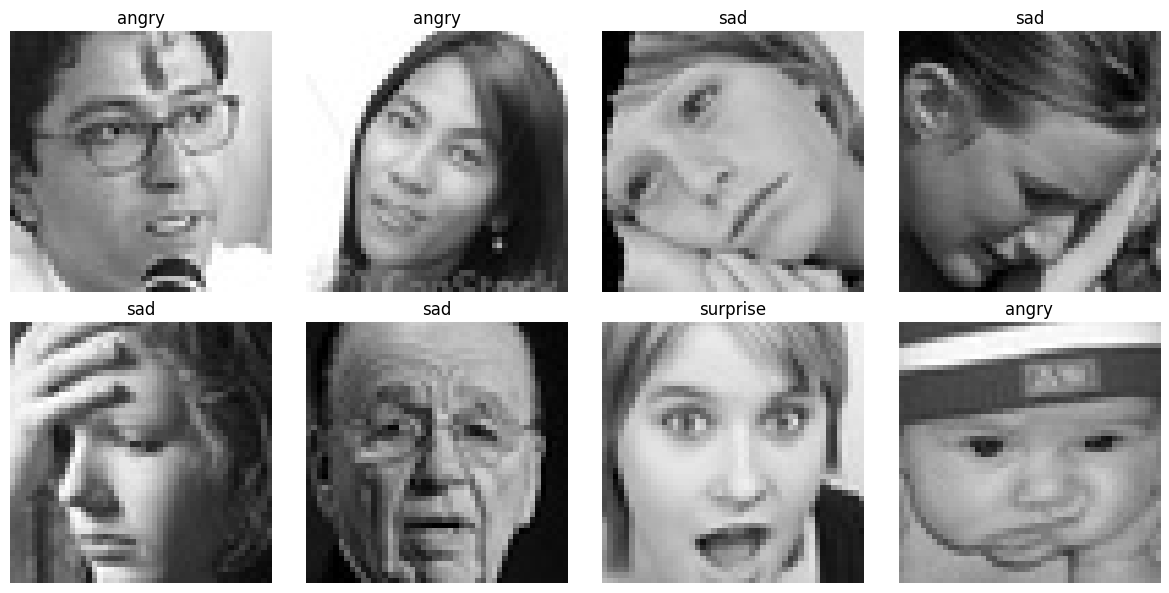

Training batches: 898
Testing batches: 225


In [95]:
import importlib
import src.datasets.datasets as ds

importlib.reload(ds)

train_loader = ds.train_loader
test_loader = ds.test_loader

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

In [96]:
from src.datasets.datasets import train_loader, test_loader

for t in range(EPOCH):
    print(f"Epoch {t+1} \n-----------------------------")
    train(train_loader, model,loss_fn,optimizer)
    test(test_loader,model,loss_fn)

Epoch 1 
-----------------------------
loss: 1.928423 [32]/28709
loss: 1.732023 [3232]/28709
loss: 1.747519 [6432]/28709
loss: 1.589396 [9632]/28709
loss: 1.327830 [12832]/28709
loss: 1.641976 [16032]/28709
loss: 1.488781 [19232]/28709
loss: 1.321623 [22432]/28709
loss: 1.450069 [25632]/28709
Test Error:
 Accuracy: 46.3%, Avg loss: 1.401277

Prediction: neutral | Actual: angry
Prediction: sad | Actual: angry
Prediction: sad | Actual: angry
Prediction: happy | Actual: angry
Prediction: angry | Actual: angry
Prediction: fear | Actual: angry
Prediction: neutral | Actual: angry
Prediction: angry | Actual: angry
Epoch 2 
-----------------------------
loss: 1.106269 [32]/28709
loss: 1.346328 [3232]/28709
loss: 1.500487 [6432]/28709
loss: 1.605356 [9632]/28709
loss: 1.575410 [12832]/28709
loss: 1.327131 [16032]/28709
loss: 1.718538 [19232]/28709
loss: 1.051320 [22432]/28709
loss: 1.332051 [25632]/28709
Test Error:
 Accuracy: 50.0%, Avg loss: 1.282866

Prediction: sad | Actual: angry
Predictio